In [1]:
import numpy as np

rng = np.random.default_rng(0)

X0 = rng.normal(size=(500, 1000))
X0[:, 0] *= 5

print("数据形状：", X0.shape)
print("第一行的前 3 个数：", X0[0, :3].round(3))

数据形状： (500, 1000)
第一行的前 3 个数： [ 0.629 -0.132  0.64 ]


In [4]:
import numpy as np

# 1. 生成三条示例数据。真实答案等于第一个特征，观测答案带有噪声。
rng = np.random.default_rng(42)
X = rng.normal(loc=0, scale=[5, 1], size=(3, 2))
y_true = X[:, 0]
y_train = y_true + rng.normal(loc=0, scale=1, size=3)

# 2. 老师用第一条输入和它的观测答案训练。[:1] 表示只取第一条。
X_train = X[:1]
y_observed = y_train[:1]
beta_0 = np.linalg.lstsq(X_train, y_observed, rcond=None)[0]

# 3. 老师给新题 (1, 1) 写答案，学生用这道题和老师的答案训练。
X_fresh = np.array([[1.0, 1.0]])
pseudo_label = X_fresh @ beta_0
beta_1 = np.linalg.lstsq(X_fresh, pseudo_label, rcond=None)[0]

print("老师的系数：", beta_0.round(4))
print("老师给新题的答案：", pseudo_label.round(4))
print("学生的系数：", beta_1.round(4))

老师的系数： [ 0.7394 -0.5047]
老师给新题的答案： [0.2347]
学生的系数： [0.1173 0.1173]


In [5]:
import numpy as np
import pandas as pd

# 第一行是学生训练时见过的题。
# 第二行只把 x2 从 1 改成 -1，学生训练时没见过。
X_check = np.array([
    [1.0,  1.0],
    [1.0, -1.0]
])

# 这个小例子的真实规律是 y = x1，所以两道题的真实答案都是 1。
# @ 表示把每个特征乘以它对应的系数，再把结果加起来。
check = pd.DataFrame({
    "x1": X_check[:, 0],
    "x2": X_check[:, 1],
    "真实答案": X_check[:, 0],
    "老师预测": X_check @ np.asarray(beta_0).reshape(-1),
    "学生预测": X_check @ np.asarray(beta_1).reshape(-1),
}, index=["训练时见过的题", "换一道新题"])

display(check.round(3))

,x1,x2,真实答案,老师预测,学生预测
训练时见过的题,1.0,1.0,1.0,0.235,0.235
换一道新题,1.0,-1.0,1.0,1.244,-0.000


In [6]:
import numpy as np
import pandas as pd

# 1. 设置本次实验规模，固定随机种子，方便重复运行
rng = np.random.default_rng(0)
n_train = 500
n_features = 1000
n_test = 2000

# 2. 生成训练数据
X_train = rng.normal(size=(n_train, n_features))
X_train[:, 0] *= 5                     # 第一个特征的标准差为 5，方差为 25
y_train_true = X_train[:, 0].copy()     # 真实规律：y = x1
noise = rng.normal(size=n_train)        # 每条训练样本都有自己的噪声
y_train = y_train_true + noise          # 老师训练时看到的答案

# 3. 用带噪声的答案训练第 0 轮老师
beta_teacher = np.linalg.lstsq(X_train, y_train, rcond=None)[0]

# 4. 生成 2,000 条新的测试样本，用已知的真实规律给它们写出标准答案
X_test = rng.normal(size=(n_test, n_features))
X_test[:, 0] *= 5
y_test_true = X_test[:, 0].copy()

# 5. 老师做测试题，逐题计算平方误差
pred_teacher = X_test @ beta_teacher
squared_errors = (pred_teacher - y_test_true) ** 2
mse_round_0 = squared_errors.mean()

# 先看前五道题，再看全部 2,000 道题的平均成绩
preview = pd.DataFrame({
    "真实答案": y_test_true[:5],
    "老师预测": pred_teacher[:5],
    "平方误差": squared_errors[:5]
})
display(preview.round(4))
print(f"第 0 轮老师的测试 MSE（全部 {n_test} 条）= {mse_round_0:.4f}")

,真实答案,老师预测,平方误差
0,0.9001,1.4260,0.2766
1,5.9418,5.0852,0.7337
2,-0.7318,-1.0762,0.1186
3,-0.6920,1.2882,3.9212
4,3.7900,2.0727,2.9492


第 0 轮老师的测试 MSE（全部 2000 条）= 1.1493


In [7]:
# 1. 生成 500 条新输入。固定种子，重复运行这一格会得到相同结果。
rng_round_1 = np.random.default_rng(1)
X_fresh = rng_round_1.normal(size=(n_train, n_features))
X_fresh[:, 0] *= 5  # 和上一格保持相同的数据分布

# 2. 老师给这 500 条新输入写答案：这就是伪标签
pseudo_labels = X_fresh @ beta_teacher

# 3. 学生用新输入和伪标签训练，得到第 1 轮模型
beta_student_1 = np.linalg.lstsq(X_fresh, pseudo_labels, rcond=None)[0]

# 4. 检查学生在这 500 道训练题上，和老师最多差多少
student_train_pred = X_fresh @ beta_student_1
max_gap = np.max(np.abs(student_train_pred - pseudo_labels))
print(f"训练题上，学生和老师的最大预测差 = {max_gap:.2e}")

# 5. 用上一格完全相同的 2,000 道测试题给学生打分
pred_student_1 = X_test @ beta_student_1
mse_round_1 = np.mean((pred_student_1 - y_test_true) ** 2)

comparison = pd.DataFrame({
    "模型": ["第 0 轮老师", "第 1 轮学生"],
    "测试 MSE": [mse_round_0, mse_round_1]
})
display(comparison.round(4))

print(f"测试 MSE 变化（学生减老师）= {mse_round_1 - mse_round_0:+.4f}")

训练题上，学生和老师的最大预测差 = 4.51e-14


,模型,测试 MSE
0,第 0 轮老师,1.1493
1,第 1 轮学生,0.7412


测试 MSE 变化（学生减老师）= -0.4081


,轮数,测试 MSE
0,0,1.1493
1,1,0.7412
2,2,0.7333
3,3,0.8556
4,4,1.0085
5,5,1.2815
6,6,1.6263
7,7,2.1159
8,8,2.4651
9,9,2.8773


本次测试 MSE 最低的是第 2 轮：0.7333
第 15 轮的测试 MSE：5.6904


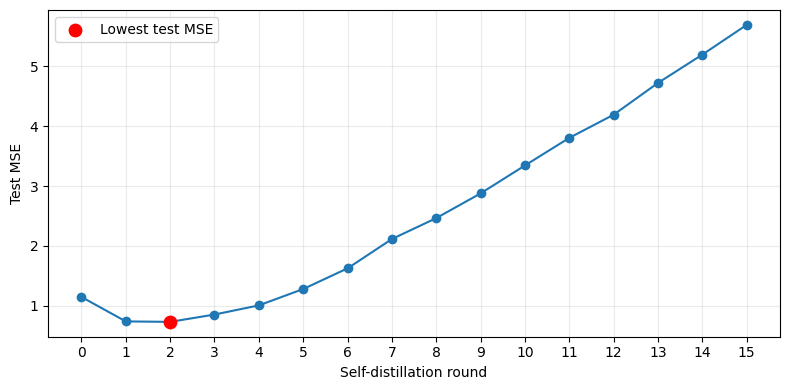

In [8]:
import matplotlib.pyplot as plt

test_mses = [mse_round_0, mse_round_1]
beta_previous = beta_student_1.copy()

for round_id in range(2, 16):
    # 每轮换一批训练输入，用轮数作种子，方便重复实验
    rng_round = np.random.default_rng(round_id)
    X_round = rng_round.normal(size=(n_train, n_features))
    X_round[:, 0] *= 5

    # 上一轮模型写伪标签，本轮学生学习这些答案
    pseudo_labels = X_round @ beta_previous
    beta_current = np.linalg.lstsq(X_round, pseudo_labels, rcond=None)[0]

    # 在同一套测试题上打分，并保存本轮成绩
    predictions = X_test @ beta_current
    test_mses.append(np.mean((predictions - y_test_true) ** 2))

    # 本轮学生成为下一轮的老师
    beta_previous = beta_current

# 列出全部 16 个成绩，包括作为起点的第 0 轮
history = pd.DataFrame({
    "轮数": range(len(test_mses)),
    "测试 MSE": test_mses
})
display(history.round(4))

lowest_round = int(np.argmin(test_mses))
print(f"本次测试 MSE 最低的是第 {lowest_round} 轮：{test_mses[lowest_round]:.4f}")
print(f"第 15 轮的测试 MSE：{test_mses[15]:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(history["轮数"], history["测试 MSE"], marker="o")
plt.scatter(lowest_round, test_mses[lowest_round],
            color="red", s=80, zorder=3, label="Lowest test MSE")
plt.xlabel("Self-distillation round")
plt.ylabel("Test MSE")
plt.xticks(range(16))
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [9]:
# 两列答案分别对应 A（带噪声）和 B（干净）。
# 一次求解同时训练两个模型，两列系数始终各走各的训练路线。
labels = np.column_stack([y_train, y_train_true])
weights = np.linalg.lstsq(X_train, labels, rcond=None)[0]

rows = []

for t in range(16):
    if t > 0:
        # 和前面完全相同：第 t 轮使用种子 t 生成新输入
        rng_t = np.random.default_rng(t)
        X_round = rng_t.normal(size=(n_train, n_features))
        X_round[:, 0] *= 5

        # 每个老师只给自己的学生生成伪标签
        pseudo = X_round @ weights
        weights = np.linalg.lstsq(X_round, pseudo, rcond=None)[0]

    predictions = X_test @ weights
    pred_A = predictions[:, 0]
    pred_B = predictions[:, 1]

    rows.append({
        "轮数": t,
        "A：原实验测试MSE": np.mean((pred_A - y_test_true) ** 2),
        "B：干净标签测试MSE": np.mean((pred_B - y_test_true) ** 2),
        "初始噪声造成的预测差异（均方）": np.mean((pred_A - pred_B) ** 2),
    })

diagnosis = pd.DataFrame(rows).set_index("轮数")
display(diagnosis.loc[[0, 1, 2, 15]].round(4))

,A：原实验测试MSE,B：干净标签测试MSE,初始噪声造成的预测差异（均方）
轮数,,,
0,1.1493,0.0664,1.0894
1,0.7412,0.1908,0.5232
2,0.7333,0.3745,0.2835
15,5.6904,5.4634,0.0024


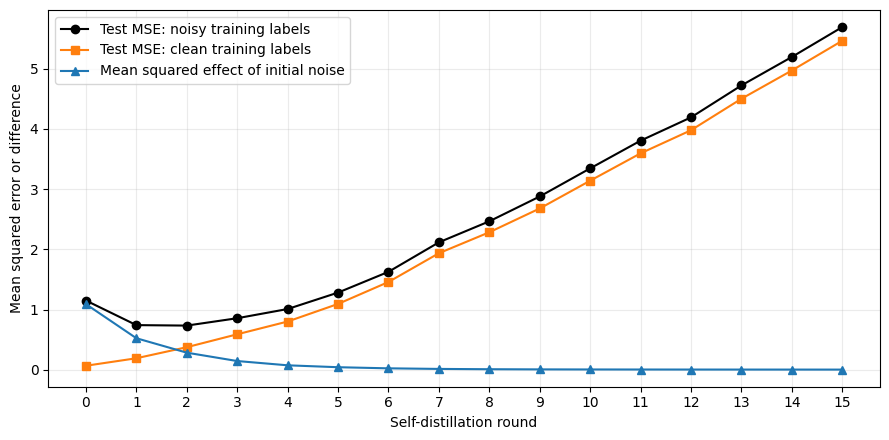

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4.5))
rounds = diagnosis.index

ax.plot(rounds, diagnosis["A：原实验测试MSE"],
        marker="o", color="black", label="Test MSE: noisy training labels")
ax.plot(rounds, diagnosis["B：干净标签测试MSE"],
        marker="s", color="tab:orange", label="Test MSE: clean training labels")
ax.plot(rounds, diagnosis["初始噪声造成的预测差异（均方）"],
        marker="^", color="tab:blue", label="Mean squared effect of initial noise")

ax.set_xlabel("Self-distillation round")
ax.set_ylabel("Mean squared error or difference")
ax.set_xticks(rounds)
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

In [11]:
import numpy as np
import pandas as pd
from threadpoolctl import threadpool_limits

# 种子 0 直接沿用你刚刚跑出来的 16 个测试 MSE
all_curves = [np.asarray(test_mses).copy()]

def draw_inputs(rng, sample_count):
    X = rng.normal(size=(sample_count, n_features))
    X[:, 0] *= 5
    return X

def run_one_seed(seed):
    # 每次实验使用不同的一组随机种子
    base = 1000 * seed
    rng = np.random.default_rng(base)

    # 初始老师：真实规律仍是 y = x1，训练答案加入噪声
    X = draw_inputs(rng, n_train)
    y = X[:, 0] + rng.normal(size=n_train)
    beta = np.linalg.lstsq(X, y, rcond=None)[0]

    # 本次实验的 16 个模型共用这一套测试题
    X_eval = draw_inputs(rng, n_test)
    y_eval = X_eval[:, 0]
    curve = [np.mean((X_eval @ beta - y_eval) ** 2)]

    for t in range(1, 16):
        X_new = draw_inputs(np.random.default_rng(base + t), n_train)
        pseudo = X_new @ beta
        beta = np.linalg.lstsq(X_new, pseudo, rcond=None)[0]
        curve.append(np.mean((X_eval @ beta - y_eval) ** 2))

    return curve

with threadpool_limits(limits=2, user_api="blas"):
    for seed in range(1, 10):
        all_curves.append(run_one_seed(seed))
        print(f"种子 {seed} 已完成")

# 每一行是一组数据，每一列是一轮自蒸馏
mse_by_seed = pd.DataFrame(all_curves)
mse_by_seed.index.name = "种子"
mse_by_seed.columns.name = "轮数"

summary = mse_by_seed[[0, 1, 2, 15]].copy()
summary.columns = ["第0轮", "第1轮", "第2轮", "第15轮"]
summary["第2轮减第0轮"] = summary["第2轮"] - summary["第0轮"]
summary["本次最低点轮数"] = mse_by_seed.idxmin(axis=1)
display(summary.round(4))

mean_curve = mse_by_seed.mean(axis=0)
print(f"第2轮优于第0轮：{(mse_by_seed[2] < mse_by_seed[0]).sum()} / 10 次")
print(f"第15轮差于第0轮：{(mse_by_seed[15] > mse_by_seed[0]).sum()} / 10 次")
print(f"10次平均后，曲线最低点在第 {mean_curve.idxmin()} 轮，"
      f"平均测试 MSE = {mean_curve.min():.4f}")

种子 1 已完成
种子 2 已完成
种子 3 已完成
种子 4 已完成
种子 5 已完成
种子 6 已完成
种子 7 已完成
种子 8 已完成
种子 9 已完成


,第0轮,第1轮,第2轮,第15轮,第2轮减第0轮,本次最低点轮数
种子,,,,,,
0,1.1493,0.7412,0.7333,5.6904,-0.4160,2
1,1.1029,0.7098,0.5906,5.2403,-0.5123,2
2,1.0580,0.7302,0.6829,6.1662,-0.3751,2
3,0.9950,0.7154,0.5831,5.8442,-0.4119,2
4,1.0856,0.7452,0.6724,5.6114,-0.4132,2
5,1.1624,0.6718,0.5678,4.8292,-0.5947,2
6,1.1059,0.6746,0.5227,5.1717,-0.5832,2
7,1.2394,0.8337,0.7244,5.7798,-0.5150,2
8,1.1449,0.8549,0.9103,6.1780,-0.2346,1


第2轮优于第0轮：10 / 10 次
第15轮差于第0轮：10 / 10 次
10次平均后，曲线最低点在第 2 轮，平均测试 MSE = 0.6639


p=750：已完成 1/10 次
p=750：已完成 2/10 次
p=750：已完成 3/10 次
p=750：已完成 4/10 次
p=750：已完成 5/10 次
p=750：已完成 6/10 次
p=750：已完成 7/10 次
p=750：已完成 8/10 次
p=750：已完成 9/10 次
p=750：已完成 10/10 次
p=1250：已完成 1/10 次
p=1250：已完成 2/10 次
p=1250：已完成 3/10 次
p=1250：已完成 4/10 次
p=1250：已完成 5/10 次
p=1250：已完成 6/10 次
p=1250：已完成 7/10 次
p=1250：已完成 8/10 次
p=1250：已完成 9/10 次
p=1250：已完成 10/10 次


,特征数 p,p/n,第0轮平均MSE,平均曲线最低点轮数,最低平均MSE,第15轮平均MSE
0,750,1.5,2.0198,5,0.6368,1.8993
1,1000,2.0,1.1224,2,0.6639,5.6369
2,1250,2.5,0.8088,1,0.6614,9.4960


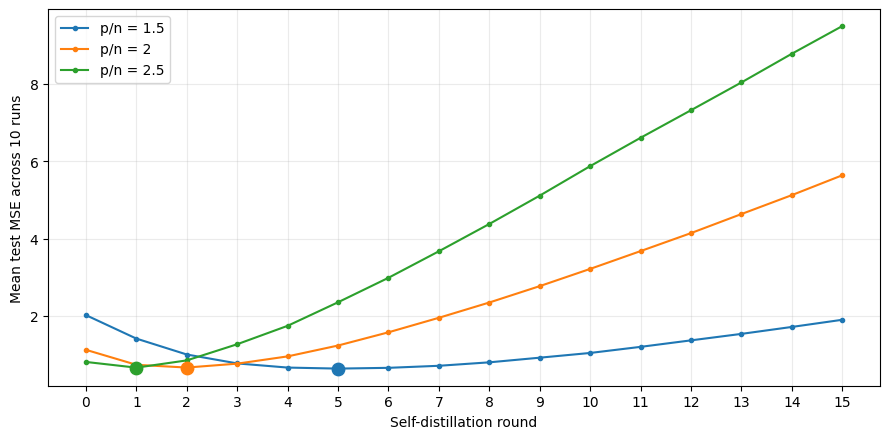

In [12]:
import matplotlib.pyplot as plt

def run_dimension_trial(p, seed):
    base = 1000 * seed
    rng = np.random.default_rng(base)

    # 每次抽取 p 个特征，保持第一个特征的方差为 25
    def draw(rng_source, sample_count):
        X = rng_source.normal(size=(sample_count, p))
        X[:, 0] *= 5
        return X

    # 第 0 轮：初始老师学习带噪声的标签
    X = draw(rng, n_train)
    y = X[:, 0] + rng.normal(size=n_train)
    beta = np.linalg.lstsq(X, y, rcond=None)[0]

    # 同一次实验的所有轮次使用同一套测试题
    X_eval = draw(rng, n_test)
    y_eval = X_eval[:, 0]
    curve = [np.mean((X_eval @ beta - y_eval) ** 2)]

    for t in range(1, 16):
        X_new = draw(np.random.default_rng(base + t), n_train)
        pseudo = X_new @ beta
        beta = np.linalg.lstsq(X_new, pseudo, rcond=None)[0]
        curve.append(np.mean((X_eval @ beta - y_eval) ** 2))

    return curve

# 保留已经算好的 p=1000，只补另外两组
curves_by_p = {1000: mse_by_seed.copy()}

with threadpool_limits(limits=2, user_api="blas"):
    for p in [750, 1250]:
        trials = []
        for seed in range(10):
            trials.append(run_dimension_trial(p, seed))
            print(f"p={p}：已完成 {seed + 1}/10 次", flush=True)
        curves_by_p[p] = pd.DataFrame(trials)

# 先在每一轮对 10 次实验取平均，再找平均曲线的最低点
rows = []
fig, ax = plt.subplots(figsize=(9, 4.5))

for p in [750, 1000, 1250]:
    mean_curve = curves_by_p[p].mean(axis=0)
    best_round = int(mean_curve.idxmin())

    rows.append({
        "特征数 p": p,
        "p/n": p / n_train,
        "第0轮平均MSE": mean_curve[0],
        "平均曲线最低点轮数": best_round,
        "最低平均MSE": mean_curve[best_round],
        "第15轮平均MSE": mean_curve[15],
    })

    line, = ax.plot(mean_curve.index, mean_curve, marker=".",
                    label=f"p/n = {p / n_train:g}")
    ax.scatter(best_round, mean_curve[best_round],
               color=line.get_color(), s=80, zorder=3)

display(pd.DataFrame(rows).round(4))

ax.set_xlabel("Self-distillation round")
ax.set_ylabel("Mean test MSE across 10 runs")
ax.set_xticks(range(16))
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

In [13]:
# 1. 只看初始训练输入，估计数据的主方向。
# 模拟输入的总体均值为 0，这里直接对未中心化的输入矩阵做 SVD。
_, _, vt = np.linalg.svd(X_train, full_matrices=False)
u = vt[0].copy()

# u 和 -u 表示同一个方向。统一符号，方便阅读输出。
largest_coordinate = np.argmax(np.abs(u))
if u[largest_coordinate] < 0:
    u = -u

# 2. 模型系数与单位向量 u 的内积，就是模型沿 u 的系数。
# beta_previous 是前面 15 轮循环结束时保留下来的第 15 轮模型。
models = [
    ("第0轮：初始老师", beta_teacher),
    ("第1轮：普通学生", beta_student_1),
    ("第15轮：普通学生", beta_previous),
]

initial_component = u @ beta_teacher
records = []

for name, beta in models:
    component = u @ beta
    records.append({
        "模型": name,
        "沿主方向的系数": component,
        "相对初始老师的保留比例": component / initial_component,
    })

display(pd.DataFrame(records).round(4))

# 3. 模拟实验中已知真实信号沿第一个特征，可以事后核验方向。
# 这一步只用于评价，不参与上面挑选 u 的过程。
print(f"估计方向与真实信号方向的余弦相似度（绝对值）：{abs(u[0]):.4f}")

,模型,沿主方向的系数,相对初始老师的保留比例
0,第0轮：初始老师,0.9568,1.000
1,第1轮：普通学生,0.8936,0.934
2,第15轮：普通学生,0.4947,0.517


估计方向与真实信号方向的余弦相似度（绝对值）：0.9620


In [14]:
# 1. 用第 1 轮的同一批输入，重新取出初始老师给的 500 个伪标签
X_round1 = X_fresh
y_round1 = X_round1 @ beta_teacher

# 2. 加入“第 501 道题”：输入为 u，答案为初始老师沿 u 的系数
target_component = u @ beta_teacher
X_protected = np.vstack([X_round1, u])
y_protected = np.append(y_round1, target_component)

# 3. 训练第 1 轮的方向保护学生
beta_protected_1 = np.linalg.lstsq(X_protected, y_protected, rcond=None)[0]

# 4. 用相同的训练题、方向和测试集，比较两个学生
results = []
for name, beta in [
    ("普通学生", beta_student_1),
    ("保护学生", beta_protected_1),
]:
    results.append({
        "第1轮模型": name,
        "500题最大伪标签误差": np.max(np.abs(X_round1 @ beta - y_round1)),
        "沿主方向的系数": u @ beta,
        "主方向系数保留比例": (u @ beta) / target_component,
        "测试MSE": np.mean((X_test @ beta - y_test_true) ** 2),
    })

comparison = pd.DataFrame(results).set_index("第1轮模型")
display(comparison.style.format({
    "500题最大伪标签误差": "{:.2e}",
    "沿主方向的系数": "{:.4f}",
    "主方向系数保留比例": "{:.1%}",
    "测试MSE": "{:.4f}",
}))

,500题最大伪标签误差,沿主方向的系数,主方向系数保留比例,测试MSE
第1轮模型,,,,
普通学生,4.51e-14,0.8936,93.4%,0.7412
保护学生,5.22e-14,0.9568,100.0%,0.6174


,普通学生MSE,保护学生MSE,保护模型沿主方向的系数,保护减普通
轮数,,,,
0,1.1493,1.1493,0.9568,0.0000
1,0.7412,0.6174,0.9568,-0.1238
2,0.7333,0.4305,0.9568,-0.3028
5,1.2815,0.2264,0.9568,-1.0551
15,5.6904,0.2099,0.9568,-5.4805


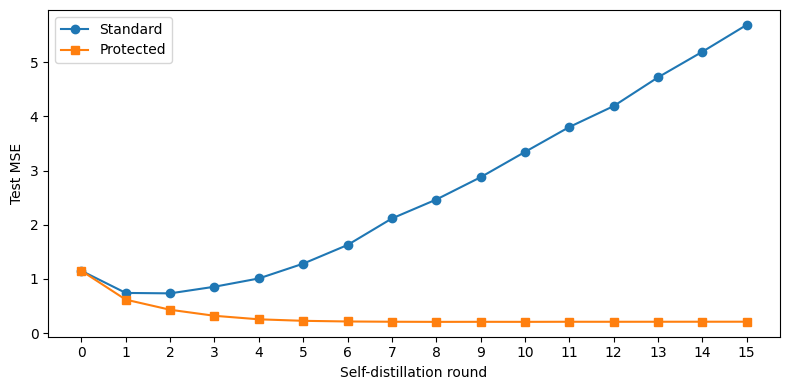

In [15]:
# 沿用已经训练好的第 1 轮保护学生，以及第 0、1 轮的成绩
beta_protected = beta_protected_1.copy()
protected_mses = [
    mse_round_0,
    np.mean((X_test @ beta_protected - y_test_true) ** 2),
]
protected_components = [target_component, u @ beta_protected]

with threadpool_limits(limits=2, user_api="blas"):
    for t in range(2, 16):
        # 重现普通学生在第 t 轮用过的同一批 500 条输入
        rng_t = np.random.default_rng(t)
        X_t = rng_t.normal(size=(n_train, n_features))
        X_t[:, 0] *= 5

        # 前 500 题由上一轮保护学生出答案；第 501 题始终用初始目标
        pseudo_t = X_t @ beta_protected
        X_aug = np.vstack([X_t, u])
        y_aug = np.append(pseudo_t, target_component)
        beta_protected = np.linalg.lstsq(X_aug, y_aug, rcond=None)[0]

        protected_mses.append(np.mean((X_test @ beta_protected - y_test_true) ** 2))
        protected_components.append(u @ beta_protected)

trajectory = pd.DataFrame({
    "普通学生MSE": mse_by_seed.loc[0].to_numpy(),
    "保护学生MSE": protected_mses,
    "保护模型沿主方向的系数": protected_components,
})
trajectory.index.name = "轮数"
trajectory["保护减普通"] = trajectory["保护学生MSE"] - trajectory["普通学生MSE"]

# 展示关键轮次，画图时保留全部 16 个点
display(trajectory.loc[[0, 1, 2, 5, 15]].round(4))

plt.figure(figsize=(8, 4))
plt.plot(trajectory.index, trajectory["普通学生MSE"], "o-", label="Standard")
plt.plot(trajectory.index, trajectory["保护学生MSE"], "s-", label="Protected")
plt.xlabel("Self-distillation round")
plt.ylabel("Test MSE")
plt.xticks(range(16))
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
def protected_mse_at_round5(seed):
    # 与之前普通模型的同一种子使用相同的训练数据、噪声和测试题
    base = 1000 * seed
    rng = np.random.default_rng(base)

    X = draw_inputs(rng, n_train)
    y = X[:, 0] + rng.normal(size=n_train)
    X_eval = draw_inputs(rng, n_test)
    y_eval = X_eval[:, 0]

    # 每个种子从自己的初始训练数据估计方向和保护目标
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    _, _, vt = np.linalg.svd(X, full_matrices=False)
    direction = vt[0]
    target = direction @ beta

    for t in range(1, 6):
        X_new = draw_inputs(np.random.default_rng(base + t), n_train)
        pseudo = X_new @ beta
        X_aug = np.vstack([X_new, direction])
        y_aug = np.append(pseudo, target)
        beta = np.linalg.lstsq(X_aug, y_aug, rcond=None)[0]

    return np.mean((X_eval @ beta - y_eval) ** 2)


protected_at_5 = [trajectory.loc[5, "保护学生MSE"]]

with threadpool_limits(limits=2, user_api="blas"):
    for seed in range(1, 10):
        protected_at_5.append(protected_mse_at_round5(seed))
        print(f"种子 {seed} 已完成", flush=True)

paired = pd.DataFrame({
    "初始老师": mse_by_seed[0],
    "普通第5轮": mse_by_seed[5],
    "保护第5轮": protected_at_5,
})
paired["保护减普通"] = paired["保护第5轮"] - paired["普通第5轮"]
paired["保护减初始"] = paired["保护第5轮"] - paired["初始老师"]

display(paired.round(4))
display(paired.mean().to_frame("10个种子的平均值").round(4))

print(f"保护优于普通第5轮：{(paired['保护减普通'] < 0).sum()} / 10 次")
print(f"保护优于初始老师：{(paired['保护减初始'] < 0).sum()} / 10 次")

种子 1 已完成
种子 2 已完成
种子 3 已完成
种子 4 已完成
种子 5 已完成
种子 6 已完成
种子 7 已完成
种子 8 已完成
种子 9 已完成


,初始老师,普通第5轮,保护第5轮,保护减普通,保护减初始
种子,,,,,
0,1.1493,1.2815,0.2264,-1.0551,-0.9229
1,1.1029,1.0940,0.2976,-0.7964,-0.8053
2,1.0580,1.3622,0.3019,-1.0602,-0.7561
3,0.9950,1.1762,0.2168,-0.9594,-0.7782
4,1.0856,1.2473,0.2649,-0.9824,-0.8207
5,1.1624,0.9756,0.2127,-0.7629,-0.9498
6,1.1059,1.0364,0.2435,-0.7930,-0.8625
7,1.2394,1.2063,0.2275,-0.9788,-1.0119
8,1.1449,1.6126,0.2755,-1.3371,-0.8694


,10个种子的平均值
初始老师,1.1224
普通第5轮,1.2334
保护第5轮,0.2464
保护减普通,-0.9870
保护减初始,-0.8760


保护优于普通第5轮：10 / 10 次
保护优于初始老师：10 / 10 次


In [17]:
def compare_at_90_percent(seed):
    base = 1000 * seed
    rng = np.random.default_rng(base)

    # 用独立的随机数选正负号，保持原来的输入和噪声抽样顺序
    sign = np.random.default_rng([seed, 9001]).choice([-1, 1])

    def true_output(X):
        return np.sqrt(0.9) * X[:, 0] + sign * 5 * np.sqrt(0.1) * X[:, 1]

    X = draw_inputs(rng, n_train)
    y = true_output(X) + rng.normal(size=n_train)
    X_eval = draw_inputs(rng, n_test)
    y_eval = true_output(X_eval)

    beta_initial = np.linalg.lstsq(X, y, rcond=None)[0]
    _, _, vt = np.linalg.svd(X, full_matrices=False)
    direction = vt[0]
    target = direction @ beta_initial

    beta_standard = beta_initial.copy()
    beta_protected = beta_initial.copy()

    for t in range(1, 6):
        X_new = draw_inputs(np.random.default_rng(base + t), n_train)

        # 两条路线共用本轮输入，各自用自己的上一轮模型生成伪标签
        y_standard = X_new @ beta_standard
        y_protected = X_new @ beta_protected

        beta_standard = np.linalg.lstsq(X_new, y_standard, rcond=None)[0]
        X_aug = np.vstack([X_new, direction])
        y_aug = np.append(y_protected, target)
        beta_protected = np.linalg.lstsq(X_aug, y_aug, rcond=None)[0]

    def test_mse(beta):
        return np.mean((X_eval @ beta - y_eval) ** 2)

    return [test_mse(beta_initial), test_mse(beta_standard), test_mse(beta_protected)]


with threadpool_limits(limits=2, user_api="blas"):
    results_90 = []
    for seed in range(10):
        results_90.append(compare_at_90_percent(seed))
        print(f"90% 信号实验：种子 {seed} 已完成", flush=True)

paired_90 = pd.DataFrame(results_90, columns=["初始老师", "普通第5轮", "保护第5轮"])
paired_90.index.name = "种子"
paired_90["保护减普通"] = paired_90["保护第5轮"] - paired_90["普通第5轮"]
paired_90["保护减初始"] = paired_90["保护第5轮"] - paired_90["初始老师"]

display(paired_90.round(4))
display(pd.DataFrame({
    "100% 信号在主方向": paired.mean(),
    "90% 信号在主方向": paired_90.mean(),
}).round(4))

90% 信号实验：种子 0 已完成
90% 信号实验：种子 1 已完成
90% 信号实验：种子 2 已完成
90% 信号实验：种子 3 已完成
90% 信号实验：种子 4 已完成
90% 信号实验：种子 5 已完成
90% 信号实验：种子 6 已完成
90% 信号实验：种子 7 已完成
90% 信号实验：种子 8 已完成
90% 信号实验：种子 9 已完成


,初始老师,普通第5轮,保护第5轮,保护减普通,保护减初始
种子,,,,,
0,2.3530,3.5069,2.6001,-0.9068,0.2471
1,2.4425,3.6001,2.8881,-0.7120,0.4457
2,2.0966,3.3276,2.5615,-0.7661,0.4649
3,2.1276,3.3471,2.5649,-0.7822,0.4373
4,2.2993,3.5838,2.8698,-0.7140,0.5705
5,2.3889,3.3427,2.6067,-0.7360,0.2178
6,2.3719,3.3035,2.6896,-0.6139,0.3177
7,2.5418,3.7248,2.7316,-0.9933,0.1898
8,2.2810,3.8275,2.5999,-1.2276,0.3189


,100% 信号在主方向,90% 信号在主方向
初始老师,1.1224,2.3230
普通第5轮,1.2334,3.5301
保护第5轮,0.2464,2.6673
保护减普通,-0.9870,-0.8628
保护减初始,-0.8760,0.3444


In [18]:
def component_changes(seed):
    base = 1000 * seed
    rng = np.random.default_rng(base)

    # 与前面实验使用相同的训练输入、噪声和测试输入
    X = draw_inputs(rng, n_train)
    noise = rng.normal(size=n_train)
    X_eval = draw_inputs(rng, n_test)

    # 三列分别代表：主方向信号、第二方向信号、纯噪声
    labels = np.column_stack([X[:, 0], 5 * X[:, 1], noise])
    truth = np.column_stack([
        X_eval[:, 0],
        5 * X_eval[:, 1],
        np.zeros(n_test),  # 纯噪声在新样本上的真实信号是 0
    ])

    beta = np.linalg.lstsq(X, labels, rcond=None)[0]
    initial_mse = np.mean((X_eval @ beta - truth) ** 2, axis=0)

    # 三列共用同一个估计方向，各自保留自己的初始系数
    _, _, vt = np.linalg.svd(X, full_matrices=False)
    direction = vt[0]
    targets = direction @ beta

    for t in range(1, 6):
        X_new = draw_inputs(np.random.default_rng(base + t), n_train)
        X_aug = np.vstack([X_new, direction])
        labels_aug = np.vstack([X_new @ beta, targets])
        beta = np.linalg.lstsq(X_aug, labels_aug, rcond=None)[0]

    protected_mse = np.mean((X_eval @ beta - truth) ** 2, axis=0)
    return protected_mse - initial_mse


with threadpool_limits(limits=2, user_api="blas"):
    changes = pd.DataFrame(
        [component_changes(seed) for seed in range(10)],
        columns=["ΔS 主方向", "ΔW 第二方向", "ΔN 噪声"],
    )

mean_changes = changes.mean()
display(mean_changes.to_frame("保护五轮减初始老师").round(4))

delta_s, delta_w, delta_n = mean_changes.to_numpy()
if np.isclose(delta_s, delta_w):
    print("这组估计没有给出唯一分界点。")
else:
    f_star = -(delta_w + delta_n) / (delta_s - delta_w)
    if 0 <= f_star <= 1:
        print(f"预测分界点：主方向承载 {f_star:.1%} 的真实信号方差")
    else:
        print("预测分界点落在 0% 到 100% 之外。")

,保护五轮减初始老师
ΔS 主方向,0.1201
ΔW 第二方向,12.0982
ΔN 噪声,-1.0039


预测分界点：主方向承载 92.6% 的真实信号方差


In [19]:
from scipy.stats import t as student_t

fractions = np.array([0.85, 0.90, 0.95, 0.975, 1.00])

# 先固定开发组给出的预测，后面不再调整
predicted_gap = (
    fractions * delta_s
    + (1 - fractions) * delta_w
    + delta_n
)

def validate_one_seed(seed):
    base = 1000 * seed
    rng = np.random.default_rng(base)
    sign = np.random.default_rng([seed, 9001]).choice([-1, 1])

    # 每列对应一个信号占比，共五列；各列的总信号方差都是 25
    def clean_labels(X):
        main = X[:, 0, None] * np.sqrt(fractions)
        second = sign * 5 * X[:, 1, None] * np.sqrt(1 - fractions)
        return main + second

    X = draw_inputs(rng, n_train)
    noise = rng.normal(size=(n_train, 1))
    y_train_all = clean_labels(X) + noise
    X_eval = draw_inputs(rng, n_test)
    y_eval_all = clean_labels(X_eval)

    # 同时训练五列模型，每列只学习自己的标签
    beta = np.linalg.lstsq(X, y_train_all, rcond=None)[0]
    initial_mse = np.mean((X_eval @ beta - y_eval_all) ** 2, axis=0)

    _, _, vt = np.linalg.svd(X, full_matrices=False)
    direction = vt[0]
    targets = direction @ beta

    for round_id in range(1, 6):
        X_new = draw_inputs(np.random.default_rng(base + round_id), n_train)
        X_aug = np.vstack([X_new, direction])
        y_aug = np.vstack([X_new @ beta, targets])
        beta = np.linalg.lstsq(X_aug, y_aug, rcond=None)[0]

    protected_mse = np.mean((X_eval @ beta - y_eval_all) ** 2, axis=0)
    return protected_mse - initial_mse


with threadpool_limits(limits=2, user_api="blas"):
    validation_gaps = []
    for seed in range(200, 230):
        validation_gaps.append(validate_one_seed(seed))
        if len(validation_gaps) % 5 == 0:
            print(f"独立检验已完成 {len(validation_gaps)}/30 个种子", flush=True)

# 每个种子先做配对差，再对 30 个差值取平均、计算逐点 95% 区间
gaps = np.asarray(validation_gaps)
observed_gap = gaps.mean(axis=0)
margin = student_t.ppf(0.975, df=29) * gaps.std(axis=0, ddof=1) / np.sqrt(30)

boundary_check = pd.DataFrame({
    "主方向信号占比": [f"{f:.1%}" for f in fractions],
    "公式预测差值": predicted_gap,
    "新种子实测差值": observed_gap,
    "95%区间下限": observed_gap - margin,
    "95%区间上限": observed_gap + margin,
})
display(boundary_check.round(4))

独立检验已完成 5/30 个种子
独立检验已完成 10/30 个种子
独立检验已完成 15/30 个种子
独立检验已完成 20/30 个种子
独立检验已完成 25/30 个种子
独立检验已完成 30/30 个种子


,主方向信号占比,公式预测差值,新种子实测差值,95%区间下限,95%区间上限
0,85.0%,0.9129,0.9584,0.8941,1.0227
1,90.0%,0.3140,0.3607,0.3088,0.4126
2,95.0%,-0.2849,-0.2369,-0.2802,-0.1937
3,97.5%,-0.5843,-0.5357,-0.5769,-0.4945
4,100.0%,-0.8838,-0.8342,-0.8768,-0.7916


In [20]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold

lambda_grid = np.array([0.01, 0.1, 1.0, 10.0, 100.0])

def compare_ridge(seed):
    rng = np.random.default_rng(1000 * seed)
    sign = np.random.default_rng([seed, 9001]).choice([-1, 1])

    # 两列分别是 100% 和 90% 信号在主方向时的干净答案
    def clean_targets(X):
        y100 = X[:, 0]
        y90 = np.sqrt(0.9) * X[:, 0] + sign * 5 * np.sqrt(0.1) * X[:, 1]
        return np.column_stack([y100, y90])

    X = draw_inputs(rng, n_train)
    y = clean_targets(X) + rng.normal(size=(n_train, 1))
    X_eval = draw_inputs(rng, n_test)
    truth = clean_targets(X_eval)

    # 每个信号设定分别选参数，两者使用相同的五折划分
    folds = KFold(n_splits=5, shuffle=True, random_state=seed)
    cv_error = np.zeros((len(lambda_grid), 2))

    for train_idx, val_idx in folds.split(X):
        for j, lam in enumerate(lambda_grid):
            # sklearn 用残差平方和，因此 alpha = 训练条数 × lambda
            model = Ridge(alpha=len(train_idx) * lam,
                          fit_intercept=False, solver="cholesky")
            model.fit(X[train_idx], y[train_idx])
            error = model.predict(X[val_idx]) - y[val_idx]
            cv_error[j] += np.mean(error ** 2, axis=0) / 5

    best_lambdas = lambda_grid[np.argmin(cv_error, axis=0)]
    scores = []
    for col, lam in enumerate(best_lambdas):
        model = Ridge(alpha=n_train * lam,
                      fit_intercept=False, solver="cholesky")
        model.fit(X, y[:, col])
        error = model.predict(X_eval) - truth[:, col]
        scores.append(np.mean(error ** 2))

    return scores


with threadpool_limits(limits=2, user_api="blas"):
    ridge_scores = []
    for seed in range(10):
        ridge_scores.append(compare_ridge(seed))
        print(f"岭回归：种子 {seed} 已完成", flush=True)

ridge_scores = pd.DataFrame(ridge_scores, columns=["100%", "90%"])
ridge_scores.index.name = "种子"

# 先看逐种子原始成绩，再看同一批种子上的平均比较
display(ridge_scores.round(4))

method_table = pd.DataFrame({
    "100% 信号在主方向": [
        paired["初始老师"].mean(), paired["普通第5轮"].mean(),
        paired["保护第5轮"].mean(), ridge_scores["100%"].mean()
    ],
    "90% 信号在主方向": [
        paired_90["初始老师"].mean(), paired_90["普通第5轮"].mean(),
        paired_90["保护第5轮"].mean(), ridge_scores["90%"].mean()
    ],
}, index=["初始老师", "普通蒸馏五轮", "方向保护五轮", "五折岭回归"])

display(method_table.round(4))

岭回归：种子 0 已完成
岭回归：种子 1 已完成
岭回归：种子 2 已完成
岭回归：种子 3 已完成
岭回归：种子 4 已完成
岭回归：种子 5 已完成
岭回归：种子 6 已完成
岭回归：种子 7 已完成
岭回归：种子 8 已完成
岭回归：种子 9 已完成


,100%,90%
种子,,
0,0.4314,1.8738
1,0.5511,2.1334
2,0.5203,1.8257
3,0.4308,1.8993
4,0.4804,2.0756
5,0.4770,1.9352
6,0.4537,1.9721
7,0.4640,2.0234
8,0.5117,2.0237


,100% 信号在主方向,90% 信号在主方向
初始老师,1.1224,2.3230
普通蒸馏五轮,1.2334,3.5301
方向保护五轮,0.2464,2.6673
五折岭回归,0.4747,1.9786


In [21]:
from scipy.linalg import solve

def evaluate_igcv(seed):
    base = 1000 * seed
    rng = np.random.default_rng(base)
    sign = np.random.default_rng([seed, 9001]).choice([-1, 1])

    def clean_targets(X):
        y100 = X[:, 0]
        y90 = np.sqrt(0.9) * X[:, 0] + sign * 5 * np.sqrt(0.1) * X[:, 1]
        return np.column_stack([y100, y90])

    X = draw_inputs(rng, n_train)
    y = clean_targets(X) + rng.normal(size=(n_train, 1))

    # mapping 把初始训练标签转换为当前轮的模型系数
    gram_inv = solve(X @ X.T, np.eye(len(X)), assume_a="pos")
    mapping = X.T @ gram_inv
    correction = (gram_inv @ y) / np.trace(gram_inv)

    scores = []
    models = []

    for t in range(16):
        if t > 0:
            X_new = draw_inputs(np.random.default_rng(base + t), n_train)
            mapping = X_new.T @ solve(
                X_new @ X_new.T, X_new @ mapping, assume_a="pos"
            )

        beta = mapping @ y
        models.append(beta)

        # 原论文 iGCV 的校正残差，只使用训练数据
        trace_h = np.einsum("ij,ji->", X, mapping)
        residual = y - X @ beta + trace_h * correction
        scores.append(np.mean(residual ** 2, axis=0))

    # 两个设定各选 iGCV 分数最低的轮次，选定后才使用测试集
    chosen = np.argmin(scores, axis=0)
    X_eval = draw_inputs(rng, n_test)
    truth = clean_targets(X_eval)
    selected_beta = np.column_stack([
        models[chosen[0]][:, 0],
        models[chosen[1]][:, 1],
    ])
    mse = np.mean((X_eval @ selected_beta - truth) ** 2, axis=0)

    # 核对 100% 设定：同一种子、同一轮应重现之前保存的测试 MSE
    np.testing.assert_allclose(mse[0], mse_by_seed.loc[seed, chosen[0]],
                               rtol=1e-7, atol=1e-9)
    return [int(chosen[0]), mse[0], int(chosen[1]), mse[1]]


with threadpool_limits(limits=2, user_api="blas"):
    igcv_rows = []
    for seed in range(10):
        igcv_rows.append(evaluate_igcv(seed))
        print(f"iGCV：种子 {seed} 已完成", flush=True)

igcv_results = pd.DataFrame(
    igcv_rows, columns=["100%所选轮数", "100%测试MSE", "90%所选轮数", "90%测试MSE"]
)
igcv_results.index.name = "种子"
display(igcv_results.round(4))

final_comparison = method_table.copy()
final_comparison.loc["普通蒸馏＋原论文iGCV选轮"] = [
    igcv_results["100%测试MSE"].mean(),
    igcv_results["90%测试MSE"].mean(),
]
display(final_comparison.round(4))

iGCV：种子 0 已完成
iGCV：种子 1 已完成
iGCV：种子 2 已完成
iGCV：种子 3 已完成
iGCV：种子 4 已完成
iGCV：种子 5 已完成
iGCV：种子 6 已完成
iGCV：种子 7 已完成
iGCV：种子 8 已完成
iGCV：种子 9 已完成


,100%所选轮数,100%测试MSE,90%所选轮数,90%测试MSE
种子,,,,
0,2,0.7333,1,2.3959
1,3,0.6170,0,2.4425
2,1,0.7302,0,2.0966
3,2,0.5831,0,2.1276
4,2,0.6724,0,2.2993
5,2,0.5678,0,2.3889
6,2,0.5227,1,2.6299
7,2,0.7244,2,2.9452
8,1,0.8549,0,2.2810


,100% 信号在主方向,90% 信号在主方向
初始老师,1.1224,2.3230
普通蒸馏五轮,1.2334,3.5301
方向保护五轮,0.2464,2.6673
五折岭回归,0.4747,1.9786
普通蒸馏＋原论文iGCV选轮,0.6657,2.3934


### Additional baseline: does one principal component explain the result?

Both models use the leading right singular vector of the initial training inputs. One-component principal component regression (PCR) fits one slope per target directly to the initial labels. The protected model retains its initial coefficient in that direction while fitting fresh pseudo-labels for five rounds. Both methods keep the original feature scales and fit through the origin.

The first table reports each matched seed. In the second, a negative gap favors protection. Each interval is a two-sided, paired 95% t interval for the mean gap across ten seeds at that signal share. The crossover studied in cells 16–17 uses the initial teacher as its baseline.

In [22]:
# Matched baseline: fit a scalar regression on the leading input direction.
def evaluate_one_component(seed):
    rng = np.random.default_rng(1000 * seed)
    sign = np.random.default_rng([seed, 9001]).choice([-1, 1])

    def clean_labels(inputs):
        first = inputs[:, 0]
        mixed = np.sqrt(0.9) * first + sign * 5 * np.sqrt(0.1) * inputs[:, 1]
        return np.column_stack([first, mixed])

    train = draw_inputs(rng, n_train)
    labels = clean_labels(train) + rng.normal(size=(n_train, 1))
    test = draw_inputs(rng, n_test)
    truth = clean_labels(test)

    # Check that both target columns use exactly the data of the earlier comparison.
    initial_weights = np.linalg.lstsq(train, labels, rcond=None)[0]
    initial_mse = np.mean((test @ initial_weights - truth) ** 2, axis=0)
    np.testing.assert_allclose(
        initial_mse, [paired.loc[seed, "初始老师"], paired_90.loc[seed, "初始老师"]]
    )

    # The protected method estimates this same direction from the initial inputs.
    # The PCR baseline fits only one slope per target and uses no distillation rounds.
    direction = np.linalg.svd(train, full_matrices=False)[2][0]
    train_coordinate = train @ direction
    slopes = (train_coordinate @ labels) / (train_coordinate @ train_coordinate)
    predictions = (test @ direction)[:, None] * slopes
    return np.mean((predictions - truth) ** 2, axis=0)


with threadpool_limits(limits=2, user_api="blas"):
    pcr_mse = np.array([evaluate_one_component(seed) for seed in paired.index])

pcr_runs = []
pcr_summary_rows = []
for j, (share, earlier) in enumerate([(1.0, paired), (0.9, paired_90)]):
    runs = pd.DataFrame({
        "seed": paired.index,
        "signal_share": share,
        "pcr_mse": pcr_mse[:, j],
        "protected_mse": earlier.loc[paired.index, "保护第5轮"].to_numpy(),
    })
    runs["gap"] = runs["protected_mse"] - runs["pcr_mse"]
    pcr_runs.append(runs)
    gaps = runs["gap"]
    half_width = student_t.ppf(0.975, df=len(gaps)-1) * gaps.sem()
    pcr_summary_rows.append({
        "signal_share": share,
        "pcr_mse": runs["pcr_mse"].mean(),
        "protected_mse": runs["protected_mse"].mean(),
        "mean_gap": gaps.mean(),
        "ci95_low": gaps.mean() - half_width,
        "ci95_high": gaps.mean() + half_width,
        "protection_wins": int((gaps < 0).sum()),
    })

pcr_by_seed = pd.concat(pcr_runs, ignore_index=True)
pcr_summary = pd.DataFrame(pcr_summary_rows)
display(pcr_by_seed.round(4))
display(pcr_summary.round(4))



,seed,signal_share,pcr_mse,protected_mse,gap
0,0,1.0,0.2105,0.2264,0.0158
1,1,1.0,0.3806,0.2976,-0.0830
2,2,1.0,0.3754,0.3019,-0.0735
3,3,1.0,0.2342,0.2168,-0.0174
4,4,1.0,0.2727,0.2649,-0.0078
5,5,1.0,0.2419,0.2127,-0.0292
6,6,1.0,0.2752,0.2435,-0.0318
7,7,1.0,0.2343,0.2275,-0.0068
8,8,1.0,0.2675,0.2755,0.0080
9,9,1.0,0.1986,0.1976,-0.0010


,signal_share,pcr_mse,protected_mse,mean_gap,ci95_low,ci95_high,protection_wins
0,1.0,0.2691,0.2464,-0.0227,-0.0462,0.0009,8
1,0.9,2.7386,2.6673,-0.0713,-0.1146,-0.0279,10
